In [1]:
%load_ext autoreload
%autoreload 2

## Data and dependencies setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OneHotEncoder

In [ ]:
df = pd.read_excel("Training-data.xlsx")
print(df.head())

        dur proto service state  spkts  dpkts  sbytes  dbytes           rate  \
0  0.000006  unas       -   INT      2      0     200       0  166909.953005   
1  0.000009   udp     dns   INT      2      0     114       0  114382.519571   
2  0.000000   arp       -   INT      1      0      46       0       0.000000   
3  0.000009  unas       -   INT      2      0     200       0  111950.270757   
4  0.000002   udp     dns   INT      2      0     114       0  507877.814866   

   sttl  ...  ct_src_dport_ltm  ct_dst_sport_ltm  ct_dst_src_ltm  \
0   254  ...                 1                 1               4   
1   254  ...                14                14              14   
2     0  ...                 2                 2               2   
3   254  ...                 3                 3               4   
4   254  ...                16                16              16   

   is_ftp_login  ct_ftp_cmd  ct_flw_http_mthd  ct_src_ltm  ct_srv_dst  \
0             0           0          

## Investigation for Data Preparation
This step will involve me analysing the characteristics and features of Training-data.xlsx and creating a comprehensive plan on the choices I will make down the line later.

In [17]:
display(df.shape)
display(df['label'].value_counts(normalize=True))

(145854, 43)

label
1    0.734138
0    0.265862
Name: proportion, dtype: float64

### Irrelevant features
From Feature_description.xlsx, we can see that 'tcprtt' is an irrelevant feature. This is because this feature is just the sum of 'synack' and 'ackdat'.

tcprtt == synack + ackdat: False
tcprtt
	Mean: 0.036547050406570955, Max: 1.482307, Min: 0.0, 
synack + ackdat
	Mean: 0.036549849390486375, Max: 1.512073, Min: 0.0, 


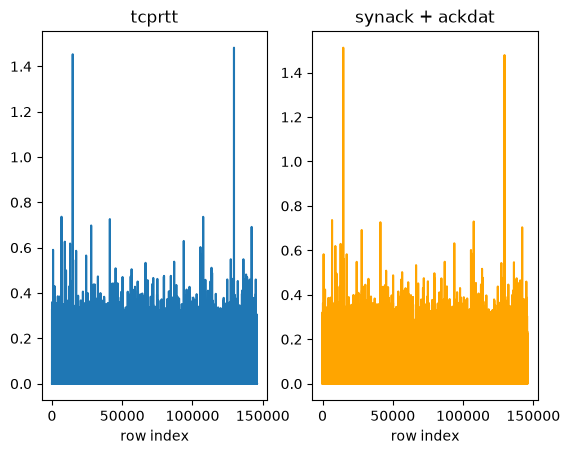

In [6]:
# Checking whether 'tcprtt' is the exact sum of 'synack' and 'ackdat'
print("tcprtt == synack + ackdat:", df['tcprtt'].equals(df['synack'] + df['ackdat']))
# Checking the distribution of 'tcprtt' and the sum of 'synack' and 'ackdat'ArithmeticError
tcprtt = df['tcprtt']
synack_ackdat = df['synack'] + df['ackdat']

print("tcprtt")
print("\tMean: {}, Max: {}, Min: {}, ".format(np.mean(tcprtt), max(tcprtt), min(tcprtt)))

print("synack + ackdat")
print("\tMean: {}, Max: {}, Min: {}, ".format(np.mean(synack_ackdat), max(synack_ackdat), min(synack_ackdat)))

fig, axes = plt.subplots(1, 2)
axes[0].plot(tcprtt)
axes[0].set_title("tcprtt")
axes[0].set_xlabel("row index")

axes[1].plot(synack_ackdat, color = 'orange')
axes[1].set_title("synack + ackdat")
axes[1].set_xlabel("row index")
plt.show()


### Missing Values
This step involves me finding rows and columns with missing values within the dataset, and decide on how to handle them.

In [15]:
# Check for the total number of missing values
print("Number of empty values: ", df.isna().sum().sum())

# Manual inspection of the values
for attr in df.select_dtypes(include=["string"]):
    print(df[attr].value_counts(normalize=True))


Number of empty values:  0
proto
tcp     0.447996
udp     0.407634
unas    0.054877
ospf    0.012732
arp     0.010003
          ...   
hmp     0.000439
egp     0.000439
icmp    0.000096
rtp     0.000007
igmp    0.000007
Name: proportion, Length: 133, dtype: float64
service
-           0.478382
dns         0.318531
http        0.108650
smtp        0.031607
ftp-data    0.025553
ftp         0.020109
ssh         0.008591
pop3        0.007130
snmp        0.000459
dhcp        0.000418
ssl         0.000357
irc         0.000144
radius      0.000069
Name: proportion, dtype: float64
state
INT    0.472534
FIN    0.446748
CON    0.074012
REQ    0.006061
RST    0.000548
ECO    0.000075
URN    0.000007
no     0.000007
PAR    0.000007
Name: proportion, dtype: float64


#### The "service" attribute
I have found that ~47% of "service" values is '-' -- unused. With around half of the column containing no values, I am considering the removal of this column. However, I am unsure whether the column being empty influences the 'label' attribute, and thereby removing this attribute will affect the model's ability to classify the data accurately. For now, I will keep the attribute within the dataset.

In [16]:
print("Proportion of 'service' entries that are 'unused':")
print("{:.4f}".format(len(df[df["service"] == '-']) / len(df["service"])))

display(df.groupby(df['service'].eq('-'))['label'].value_counts(normalize=True))

Proportion of 'service' entries that are 'unused':
0.4784


service  label
False    1        0.787250
         0        0.212750
True     1        0.676226
         0        0.323774
Name: proportion, dtype: float64

### Duplicated Values
Finding any rows are columns that are repeated within the dataset, and investigating whether it is a legitimate duplication or an erroneous one.

Running the code below tells us that there are 355 duplicated rows and 2 duplicated columns within the dataset. As the duplicated rows make up less than 0.3% of the dataset, I will leave them in for now. For the columns, an entire column duplicating is very unlikely, especially when there is 140,000+ entries, therefore I am considering this an error/mistake, and I will drop the column.

In [18]:
duplicated_rows = df.duplicated(keep=False)
duplicated_cols = df.T.duplicated(keep=False)

In [19]:
print("No. of duplicated rows:",duplicated_rows.sum())
print("No. of duplicated cols:",duplicated_cols.sum())

display(df[duplicated_rows])
display(df.T[duplicated_cols])

No. of duplicated rows: 355
No. of duplicated cols: 2


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
146,0.000000,arp,-,INT,1,0,46,0,0.0,0,...,2,2,2,0,0,0,2,2,1,0
252,0.000000,arp,-,INT,1,0,46,0,0.0,0,...,2,2,2,0,0,0,2,2,1,0
402,0.000018,mobile,-,INT,1,0,60,0,0.0,0,...,2,2,4,0,0,0,4,4,0,1
562,0.000000,arp,-,INT,1,0,46,0,0.0,0,...,2,2,2,0,0,0,2,2,1,0
574,0.000014,mobile,-,INT,1,0,60,0,0.0,0,...,3,3,4,0,0,0,3,4,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
142903,0.000000,arp,-,INT,1,0,46,0,0.0,0,...,2,2,2,0,0,0,2,2,1,0
143322,0.000009,sun-nd,-,INT,1,0,60,0,0.0,0,...,3,3,4,0,0,0,3,4,0,1
143460,0.000010,sun-nd,-,INT,1,0,60,0,0.0,0,...,1,1,2,0,0,0,1,2,0,1
143976,0.000047,swipe,-,INT,1,0,60,0,0.0,0,...,3,3,4,0,0,0,3,4,0,1


,0,1,2,3,4,5,6,7,8,9,...,145844,145845,145846,145847,145848,145849,145850,145851,145852,145853
is_ftp_login,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ct_ftp_cmd,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Data Types
Investigating the data types of the attributes and ensuring that they can be converted into appropriate types for the classification model. The dataset has three categorical attributes: proto, service, state. For each, I will create a one-hot-encoder, which is a binary array that represents the categorical value as a numeric type.

It is crucial to keep in mind that this preprocessing step will run after the data splitting, as doing it beforehand will lead to data leakage, where the information from the validation set can be present within the one-hot-encoder arrays. I still don't know how, but I am assumming that it will affect the length of the array, showing all the different possible values that it can take, even though it does not exist within the training set.

In [20]:
# Investigating how many unique values each categorical attribute has
for attr in df.select_dtypes(include=['string']):
    print(attr, len(df[attr].unique()))

proto 133
service 13
state 9


In [21]:
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded_df = encoder.fit_transform(df.select_dtypes(include=['string']))

print(encoder.get_feature_names_out())

['proto_3pc' 'proto_a/n' 'proto_aes-sp3-d' 'proto_any' 'proto_argus'
 'proto_aris' 'proto_arp' 'proto_ax.25' 'proto_bbn-rcc' 'proto_bna'
 'proto_br-sat-mon' 'proto_cbt' 'proto_cftp' 'proto_chaos'
 'proto_compaq-peer' 'proto_cphb' 'proto_cpnx' 'proto_crtp' 'proto_crudp'
 'proto_dcn' 'proto_ddp' 'proto_ddx' 'proto_dgp' 'proto_egp' 'proto_eigrp'
 'proto_emcon' 'proto_encap' 'proto_etherip' 'proto_fc' 'proto_fire'
 'proto_ggp' 'proto_gmtp' 'proto_gre' 'proto_hmp' 'proto_i-nlsp'
 'proto_iatp' 'proto_ib' 'proto_icmp' 'proto_idpr' 'proto_idpr-cmtp'
 'proto_idrp' 'proto_ifmp' 'proto_igmp' 'proto_igp' 'proto_il' 'proto_ip'
 'proto_ipcomp' 'proto_ipcv' 'proto_ipip' 'proto_iplt' 'proto_ipnip'
 'proto_ippc' 'proto_ipv6' 'proto_ipv6-frag' 'proto_ipv6-no'
 'proto_ipv6-opts' 'proto_ipv6-route' 'proto_ipx-n-ip' 'proto_irtp'
 'proto_isis' 'proto_iso-ip' 'proto_iso-tp4' 'proto_kryptolan'
 'proto_l2tp' 'proto_larp' 'proto_leaf-1' 'proto_leaf-2' 'proto_merit-inp'
 'proto_mfe-nsp' 'proto_mhrp' 'proto_micp'

### Scaling and Standardisation
I will now investigate whether any of the numeric attributes need to be scaled or standardised. The first cell will display all of the statistical characteristics of the data. Running the code, we can see that the maximum value within the dataset is 6033838853.939805, and the minimum is 0. This means that scaling and standardisation will be required. Otherwise, certain values will significantly dominate other values.

In [22]:
import math
max_val = -math.inf
min_val = math.inf
for i in df.select_dtypes(include=['number']):
    print(i)
    print("\tmean:{:.2f}".format(np.mean(df[i]))) # mean
    print("\tmin:{:.2f}".format(min(df[i]))) # mean
    print("\tmax:{:.2f}".format(max(df[i]))) # mean
    if np.max(df[i]) > max_val:
        max_val = np.max(df[i])
    elif np.min(df[i]) < min_val:
        min_val = np.min(df[i])
print("Max: {}, Min: {}".format(max_val, min_val))

dur
	mean:1.26
	min:0.00
	max:62.70
spkts
	mean:20.58
	min:1.00
	max:9616.00
dpkts
	mean:19.39
	min:0.00
	max:6494.00
sbytes
	mean:8693.28
	min:28.00
	max:12965233.00
dbytes
	mean:15112.18
	min:0.00
	max:8645430.00
rate
	mean:97646.31
	min:0.00
	max:1045000.00
sttl
	mean:176.80
	min:0.00
	max:255.00
dttl
	mean:75.21
	min:0.00
	max:254.00
sload
	mean:70518462.40
	min:0.00
	max:6033838853.94
dload
	mean:741966.43
	min:0.00
	max:22296225.18
sloss
	mean:4.94
	min:0.00
	max:4803.00
dloss
	mean:7.10
	min:0.00
	max:3246.00
sinpkt
	mean:628.82
	min:0.00
	max:84809.90
dinpkt
	mean:78.71
	min:0.00
	max:52517.03
sjit
	mean:4408.87
	min:0.00
	max:1206483.02
djit
	mean:641.84
	min:0.00
	max:291417.72
swin
	mean:114.24
	min:0.00
	max:255.00
stcpb
	mean:961895839.26
	min:0.00
	max:4294958913.00
dtcpb
	mean:962807568.87
	min:0.00
	max:4294880419.00
dwin
	mean:114.23
	min:0.00
	max:255.00
tcprtt
	mean:0.04
	min:0.00
	max:1.48
synack
	mean:0.02
	min:0.00
	max:0.52
ackdat
	mean:0.02
	min:0.00
	max:1.45
s

#### Z-Score

In [24]:
numeric_cols = df.select_dtypes(include=['number']).columns
df_standardised = df.copy()
df_standardised[numeric_cols] = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()

max_val = -math.inf
min_val = math.inf
for i in df_standardised.select_dtypes(include=['number']):
    print(i)
    print("\tmean:{:.2f}".format(np.mean(df_standardised[i]))) # mean
    print("\tmin:{:.2f}".format(min(df_standardised[i]))) # mean
    print("\tmax:{:.2f}".format(max(df_standardised[i]))) # mean
    if np.max(df_standardised[i]) > max_val:
        max_val = np.max(df_standardised[i])
    elif np.min(df_standardised[i]) < min_val:
        min_val = np.min(df_standardised[i])
print("Max: {}, Min: {}".format(max_val, min_val))

dur
	mean:-0.00
	min:-0.21
	max:10.06
spkts
	mean:-0.00
	min:-0.15
	max:71.74
dpkts
	mean:-0.00
	min:-0.22
	max:73.88
sbytes
	mean:0.00
	min:-0.05
	max:75.71
dbytes
	mean:0.00
	min:-0.13
	max:76.82
rate
	mean:-0.00
	min:-0.59
	max:5.69
sttl
	mean:-0.00
	min:-1.70
	max:0.75
dttl
	mean:0.00
	min:-0.70
	max:1.66
sload
	mean:0.00
	min:-0.39
	max:33.10
dload
	mean:0.00
	min:-0.29
	max:8.48
sloss
	mean:0.00
	min:-0.08
	max:74.47
dloss
	mean:-0.00
	min:-0.17
	max:79.54
sinpkt
	mean:0.00
	min:-0.11
	max:14.81
dinpkt
	mean:-0.00
	min:-0.09
	max:58.52
sjit
	mean:0.00
	min:-0.11
	max:30.90
djit
	mean:0.00
	min:-0.15
	max:68.27
swin
	mean:-0.00
	min:-0.90
	max:1.11
stcpb
	mean:-0.00
	min:-0.71
	max:2.47
dtcpb
	mean:0.00
	min:-0.71
	max:2.46
dwin
	mean:-0.00
	min:-0.90
	max:1.11
tcprtt
	mean:0.00
	min:-0.53
	max:21.06
synack
	mean:0.00
	min:-0.50
	max:13.91
ackdat
	mean:0.00
	min:-0.52
	max:40.81
smean
	mean:0.00
	min:-0.52
	max:6.78
dmean
	mean:-0.00
	min:-0.50
	max:4.94
trans_depth
	mean:-0.00
	m

This code will now show the new standardised mean, min, max, and standard deviation.

In [ ]:
max_val = -math.inf
min_val = math.inf
for i in df_standardised.select_dtypes(include=['number']):
    print(i)
    print("\tmean:{:.2f}".format(np.mean(df_standardised[i]))) # mean
    print("\tmin:{:.2f}".format(min(df_standardised[i]))) # mean
    print("\tmax:{:.2f}".format(max(df_standardised[i]))) # mean
    print("\tstd:{:.2f}".format(df_standardised[i].std()))
    if np.max(df_standardised[i]) > max_val:
        max_val = np.max(df_standardised[i])
    elif np.min(df_standardised[i]) < min_val:
        min_val = np.min(df_standardised[i])
print("Max: {}, Min: {}".format(max_val, min_val))

### Feature/Attribute Selection

<Axes: >

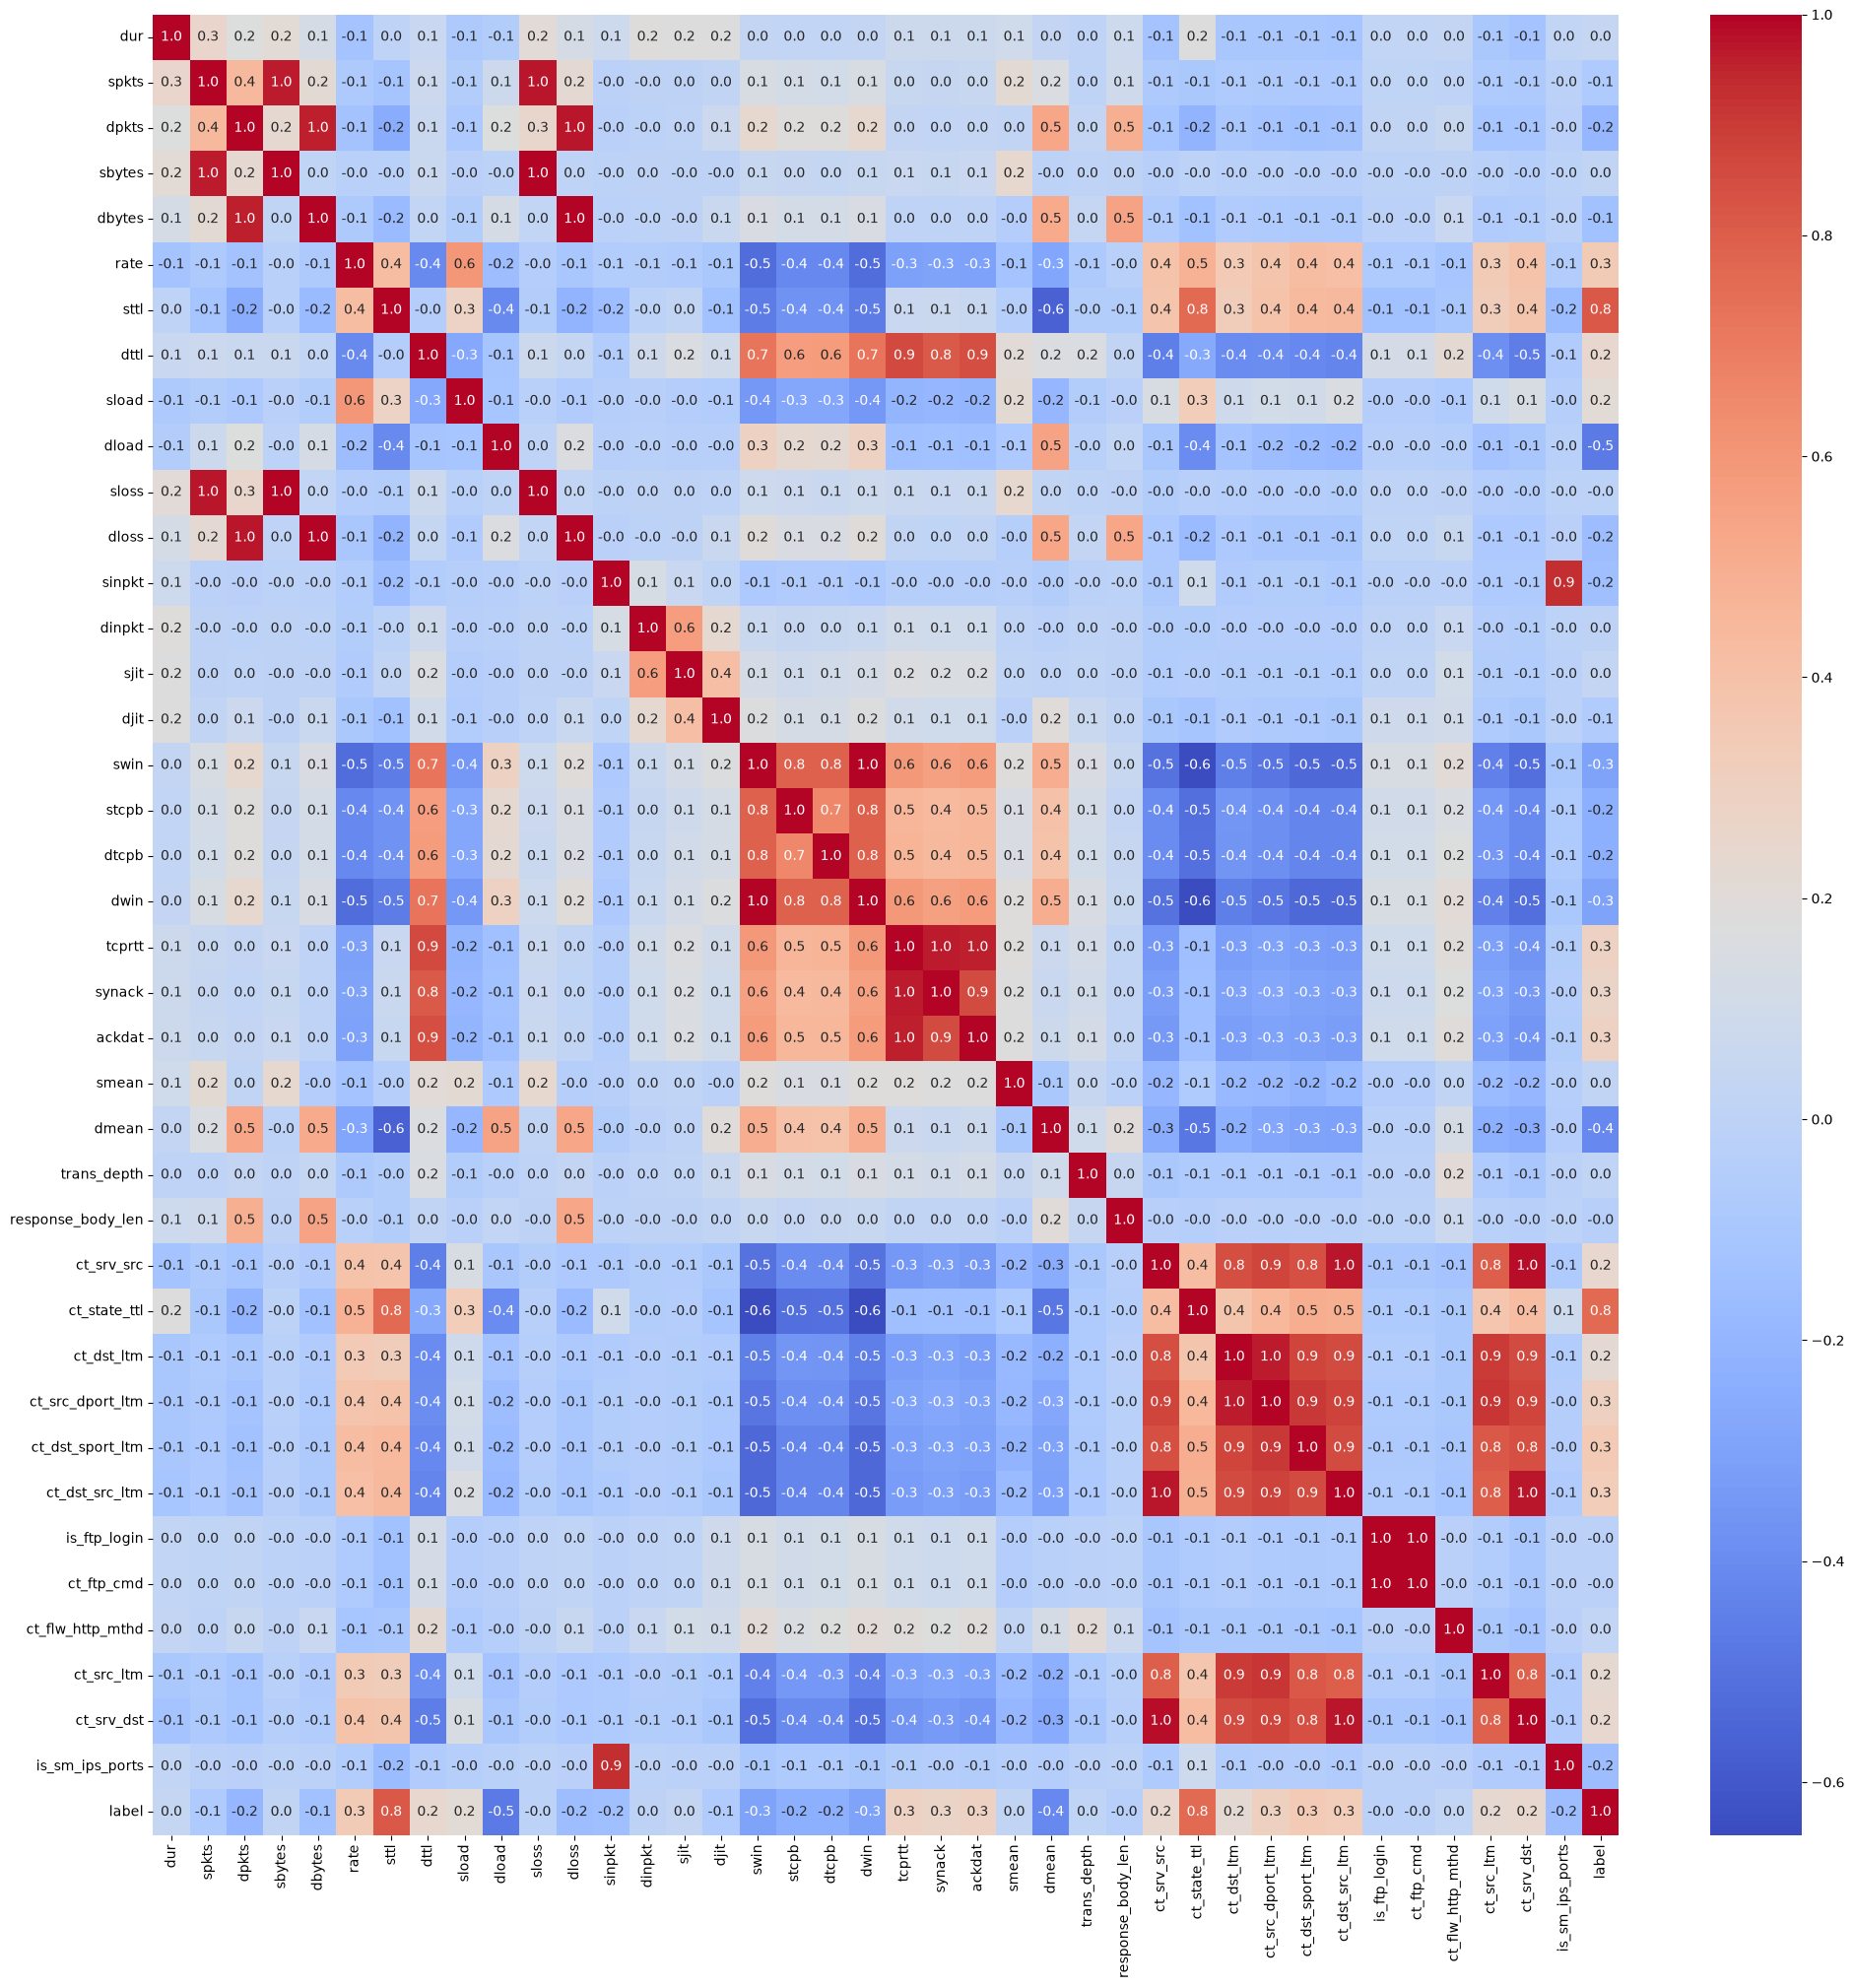

In [4]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(24,24))
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.1f')

In [5]:
# GEMINI GENERATED

upper_tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

corr_pairs = upper_tri.unstack().dropna()

sorted_pairs = corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index)

display(sorted_pairs[sorted_pairs >= 0.95])

ct_ftp_cmd        is_ftp_login      1.000000
dwin              swin              0.999965
sloss             sbytes            0.997310
dloss             dbytes            0.993889
ct_srv_dst        ct_srv_src        0.981141
                  ct_dst_src_ltm    0.974134
sloss             spkts             0.971314
ct_dst_src_ltm    ct_srv_src        0.969176
dloss             dpkts             0.968572
ct_src_dport_ltm  ct_dst_ltm        0.967416
synack            tcprtt            0.964176
sbytes            spkts             0.963762
ackdat            tcprtt            0.960973
dbytes            dpkts             0.955898
dtype: float64

From the cell above, we can see that these pairs have unusually high correlation:
- dwin vs swin
- sloss vs sbytes
- dloss vs dbytes
- ct_srv_dst vs ct_srv_src
- ct_srv_dst vs ct_dst_src_ltm  
- sloss vs spkts
- ct_dst_src_ltm vs ct_srv_src
- dloss vs dpkts
- ct_src_dport_ltm vs ct_dst_ltm
- synack vs tcprtt
- sbytes vs spkts
- ackdat vs tcprtt
- dbytes vs dpkts

In [25]:
print("dwin vs swin")
print(df[["swin", "dwin"]].describe())

print("\nsloss vs sbytes")
print(df[["sloss", "sbytes"]].describe())

print("\ndloss vs dbytes")
print(df[["dloss", "dbytes"]].describe())

dwin vs swin
                swin           dwin
count  145854.000000  145854.000000
mean      114.238965     114.234125
std       126.808932     126.808003
min         0.000000       0.000000
25%         0.000000       0.000000
50%         0.000000       0.000000
75%       255.000000     255.000000
max       255.000000     255.000000

sloss vs sbytes
               sloss        sbytes
count  145854.000000  1.458540e+05
mean        4.936395  8.693283e+03
std        64.433786  1.711424e+05
min         0.000000  2.800000e+01
25%         0.000000  1.140000e+02
50%         0.000000  3.640000e+02
75%         3.000000  1.514000e+03
max      4803.000000  1.296523e+07

dloss vs dbytes
               dloss        dbytes
count  145854.000000  1.458540e+05
mean        7.104289  1.511218e+04
std        40.718641  1.123437e+05
min         0.000000  0.000000e+00
25%         0.000000  0.000000e+00
50%         0.000000  1.780000e+02
75%         3.000000  1.634000e+03
max      3246.000000  8.645430e+06

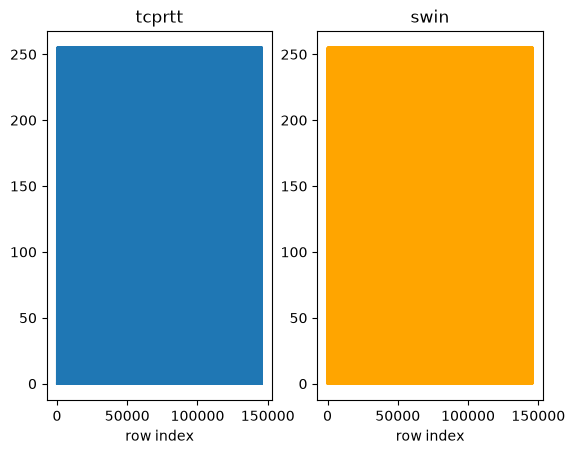

In [32]:
fig, axes = plt.subplots(1, 2)
axes[0].plot(df['dwin'].index, df['dwin'])
axes[0].set_title("tcprtt")
axes[0].set_xlabel("row index")

axes[1].plot(df['swin'], color = 'orange')
axes[1].set_title("swin")
axes[1].set_xlabel("row index")
plt.show()

After inspecting the pairs, I have decided to drop either 'swin' or 'dwin'.

### Data Instances
This preprocessing step would be relevant if I do decide to remove any of the 355 duplicated rows from earlier. It would also be relevant if I do decide to sample the data in a way that represents both classes equally.

As seen through the code below, around 73% of the network activity entries is malicious. My intuition is telling me that this overrepresentation will affect the final model, where it would be more likely to classify an activity as malicious, as opposed to normal. However, I will not do anything relating to data instances, for now.

In [ ]:
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True))

### Class Imbalance
Within this step, I am to investigate whether the proportion of malicious samples to normal samples will affect the classification model's effectiveness. This pre-processing step can be tested through cross-validation, therefore it can be implemented later down the line.

In [ ]:
print(df.skew(numeric_only=True).sort_values(ascending = False))

trans_depth          158.039508
response_body_len     81.025400
sbytes                45.752922
sloss                 45.449774
spkts                 40.695349
dinpkt                32.152381
djit                  29.549015
ct_flw_http_mthd      24.813918
dloss                 20.423925
dbytes                19.917774
sjit                  18.783469
dpkts                 17.540699
is_sm_ips_ports       10.149394
sinpkt                10.144452
ct_ftp_cmd             9.557100
is_ftp_login           9.557100
sload                  9.143010
dur                    7.864400
dload                  4.440496
smean                  3.832542
rate                   3.272362
ackdat                 2.903927
dmean                  2.663916
synack                 2.240848
tcprtt                 2.029211
ct_src_dport_ltm       1.895458
ct_dst_ltm             1.808448
ct_src_ltm             1.651040
ct_dst_sport_ltm       1.399764
ct_dst_src_ltm         1.354849
ct_srv_dst             1.320776
ct_srv_s

### Skewness
With these skewnesses in mind, we will perform attribute balancing on trans_depth and response_body_len.

### Feature Engineering
Investigating whether or not I can create new attributes or collapse attributes through finding relationships between the attributes.

The cell below shows how "src_avg_pkt_size" is just "sbytes" divided by "spkts". Which is interesting because their correlation value within the matrix was extremely low. This is likely because the correlation matrix measured the "Pearson" coefficient, which is essentially the linear relationship between the attributes, and these relationships are not so linear. This is the same case for "dest_avg_pkt_size", "dbytes", and "dpkts".

In [ ]:
display(df[["smean","sbytes","spkts"]].head(10))
display(df[["dmean","dbytes","dpkts"]].head(10))

,smean,sbytes,spkts
0,100,200,2
1,57,114,2
2,46,46,1
3,100,200,2
4,57,114,2
5,51,1322,26
6,168,2354,14
7,57,114,2
8,57,114,2
9,84,168,2


,dmean,dbytes,dpkts
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0
5,74,1620,22
6,213,2134,10
7,0,0,0
8,0,0,0
9,0,0,0


This cell shows the conversely low correlation between these attributes.

In [18]:
display(df[["smean","sbytes","spkts"]].corr())
display(df[["dmean","dbytes","dpkts"]].corr())

,smean,sbytes,spkts
smean,1.000000,0.236552,0.220144
sbytes,0.236552,1.000000,0.963762
spkts,0.220144,0.963762,1.000000


,dmean,dbytes,dpkts
dmean,1.000000,0.513131,0.533281
dbytes,0.513131,1.000000,0.955898
dpkts,0.533281,0.955898,1.000000


## Investigation for Cross-Validation